# Classification metrics

Câu lạc bộ chỉ có vài buổi cần thêm người hỗ trợ. Ta muốn một mô hình cảnh báo trước những buổi ấy. Trong 100 buổi, nếu chỉ ba buổi thật sự cần hỗ trợ, phương án luôn trả không cần vẫn đúng 97 buổi. Accuracy 97% nghe tốt, nhưng mô hình bỏ sót toàn bộ ba buổi quan trọng.



Ta cần đọc loại sai nào đang xảy ra, rồi chọn thước đo và ngưỡng phù hợp. Bài này đi từ bốn ô confusion matrix đến precision, recall, F1, ROC-AUC và xác suất. Câu hỏi luôn là: một con số đang chấm **nhãn**, **thứ tự**, hay **mức tự tin** của mô hình?

> **Sau bài này, có thể**
>
> - Tính tay confusion matrix, accuracy, precision, recall và F1.
> - Phân biệt metric dùng nhãn với ROC-AUC dùng score chưa cắt ngưỡng.
> - Chọn threshold trên validation rồi chấm test độc lập với threshold đã chốt.
> - Đọc mất cân bằng lớp, macro/weighted averaging và lỗi của xác suất quá tự tin.

## Bốn ô trước một con số tổng

Quy ước lớp dương (positive) là **cần hỗ trợ**, nhãn 1. Lớp âm (negative), nhãn 0, là chưa cần hỗ trợ. Dương không có nghĩa tốt, âm không có nghĩa xấu; chúng là tên hai vai trò trong phép đo.



True positive (TP) là báo cần và thật sự cần. False positive (FP) là báo cần nhưng thật sự chưa cần. False negative (FN) là báo chưa cần nhưng thật sự cần. True negative (TN) là báo chưa cần và đúng là chưa cần.

Một buổi có thể chỉ vào một ô. Tổng bốn ô bằng số mẫu. Trong scikit-learn, với `labels=[0,1]`, ma trận là `[[TN,FP],[FN,TP]]`. Nên ghi nhãn trục trước khi đọc; không phải mọi tài liệu đều vẽ cùng chiều. Hai ô trên đường chéo, TP và TN, là đoán đúng; các ô ngoài đường chéo cho biết mô hình nhầm lớp nào thành lớp nào. Chữ dương, âm chỉ điều mô hình báo; chữ thật, giả cho biết báo đúng hay sai. Khi hai loại lỗi có giá khác nhau, nhân số lỗi với giá rồi so tổng chi phí: FP giá 1, FN giá 10 thì 20 FP và 30 FN tốn 320.

**Hỏi nhanh.** Mô hình báo buổi ấy không cần hỗ trợ, nhưng thực tế lại cần. Trường hợp này nằm ở ô nào?

- A. TP
- B. FN
- C. FP
- D. TN

<details><summary>Đáp án</summary>

B. FN

Buổi thực tế cần hỗ trợ là mẫu dương, mà mô hình lại báo âm. Đó là bỏ sót, tức FN (false negative).

</details>

## Precision, recall và F1 nhìn những nhóm khác nhau

Accuracy đo tỉ lệ dự đoán đúng trên mọi mẫu:

$$\operatorname{Accuracy}=\frac{TP+TN}{TP+FP+FN+TN}.$$

Precision hỏi: trong những buổi **đã báo cần**, bao nhiêu buổi thật sự cần? Recall hỏi: trong những buổi **thật sự cần**, bao nhiêu buổi được phát hiện? Theo bốn ô: accuracy $=(TP+TN)/n$, precision $=TP/(TP+FP)$, recall $=TP/(TP+FN)$; specificity $=TN/(TN+FP)$ là recall của lớp âm. Mô hình luôn đoán dương có recall 1 nhưng precision chỉ bằng tỉ lệ dương trong dữ liệu.

$$\operatorname{Precision}=\frac{TP}{TP+FP},\qquad
\operatorname{Recall}=\frac{TP}{TP+FN}.$$

Hai mẫu số khác nhau nên hai câu hỏi khác nhau. Precision thấp làm người hỗ trợ đi nhiều buổi không cần thiết. Recall thấp làm nhiều buổi cần hỗ trợ bị bỏ qua. Chọn ưu tiên phải từ nhiệm vụ và metric đề, không phải mặc định một metric luôn tốt nhất. Sàng lọc bệnh hay quét mã độc mà bỏ sót rất đắt, còn báo nhầm thì có người kiểm lại: ưu tiên recall. Lọc thư rác mà vứt nhầm thư công việc, hay ẩn nhầm bình luận bình thường: báo nhầm gây hại, ưu tiên precision.

F1 là trung bình điều hòa của precision $P$ và recall $R$:

$$F_1=\frac{2PR}{P+R}=\frac{2TP}{2TP+FP+FN}.$$

Nếu một trong hai đại lượng rất thấp, F1 bị kéo thấp: $P=0.5$, $R=1$ cho $F_1=2\cdot0.5\cdot1/1.5\approx0.67$, thấp hơn trung bình cộng 0.75. Nó không tính trực tiếp TN. Khi không có mẫu dự đoán dương, precision có mẫu số 0; khi không có dương thật, recall có mẫu số 0. Cần đọc quy ước của scorer. Code trong bài dùng `zero_division=0` để xử lý rõ, không che việc fold thiếu lớp.

**Hỏi nhanh.** Có TP = 3, FP = 3, FN = 1. Precision và recall lần lượt bằng bao nhiêu?

- A. $0.5$ và $0.75$
- B. $0.75$ và $0.5$
- C. $0.6$ và $0.6$
- D. $3/7$ và $0.75$

<details><summary>Đáp án</summary>

A. $0.5$ và $0.75$

Precision là $3/(3+3) = 0.5$, recall là $3/(3+1) = 0.75$. Phương án đảo ngược là nhầm mẫu số. $0.6$ là F1, không phải hai tỉ lệ kia. $3/7$ là chia TP cho tất cả các ô có chữ T, F lẫn lộn.

</details>

## Một validation nhỏ để tính và đối chiếu

Giả sử mô hình đã trả xác suất cần hỗ trợ cho mười buổi validation. Ta cố ý dùng một mảng nhỏ để tính tay; code không huấn luyện mô hình trong bài này. Score lớn hơn nghĩa là model đánh giá khả năng cần hỗ trợ cao hơn. Threshold $t$ biến score thành nhãn:

$$\hat y_i=\mathbf 1[p_i\ge t].$$

$\mathbf 1[\cdot]$ bằng 1 khi điều kiện đúng, bằng 0 khi sai. Quy tắc dùng dấu lớn hơn hay lớn hơn hoặc bằng phải thống nhất, nhất là khi score đúng bằng threshold.



In [ ]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
)

y_valid = np.array([1, 0, 1, 0, 0, 1, 0, 0, 1, 0])
p_valid = np.array([0.95, 0.80, 0.70, 0.65, 0.60, 0.55, 0.40, 0.30, 0.20, 0.10])
prediction = (p_valid >= 0.5).astype(int)
cm = confusion_matrix(y_valid, prediction, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(cm)
print('TN, FP, FN, TP:', tn, fp, fn, tp)
print(f'Accuracy={accuracy_score(y_valid, prediction):.3f}')
print(f'Precision={precision_score(y_valid, prediction, zero_division=0):.3f}')
print(f'Recall={recall_score(y_valid, prediction, zero_division=0):.3f}')
print(f'F1={f1_score(y_valid, prediction, zero_division=0):.3f}')

[[3 3]
 [1 3]]
TN, FP, FN, TP: 3 3 1 3
Accuracy=0.600
Precision=0.500
Recall=0.750
F1=0.600


Ở ngưỡng 0.5, sáu buổi được báo cần; trong đó ba buổi thật sự cần. Có bốn buổi dương thật và ta tìm được ba. Vì vậy precision 0.5, recall 0.75, F1 $=6/(6+3+1)=0.6$. Accuracy cũng bằng 0.6 ở dữ liệu này, nhưng hai metric trùng số chỉ là tình cờ.

**Hỏi nhanh.** Vẫn mười score ở trên, giờ đổi ngưỡng thành $t = 0.7$. Precision và recall lần lượt bằng bao nhiêu?

- A. $1/2$ và $2/3$
- B. $2/3$ và $1/2$
- C. $3/4$ và $3/4$
- D. $1$ và $1/4$

<details><summary>Đáp án</summary>

B. $2/3$ và $1/2$

Có ba buổi score từ 0.7 trở lên: 0.95 là dương, 0.80 là âm, 0.70 là dương. Vậy TP = 2, FP = 1. Hai buổi dương còn lại, score 0.55 và 0.20, bị bỏ sót, nên FN = 2. Precision là $2/3$, recall là $2/4$. So với ngưỡng 0.5, precision tăng còn recall giảm. F1 lúc này là 0.571, khớp với dòng `t=0.7` ở mục sau.

</details>

Trong ví dụ 100 buổi đầu bài, luôn dự đoán 0 cho TP=0, FN=3, FP=0, TN=97. Accuracy 0.97, recall 0 và F1 0 theo quy ước đang dùng. Accuracy không sai; nó trả lời một câu hỏi ít phù hợp nếu mục tiêu là tìm lớp hiếm.

## Threshold là một lựa chọn phải đánh giá

Hạ threshold làm nhiều mẫu được gọi dương hơn: recall không bao giờ giảm, còn precision lên hay xuống tùy mẫu mới được thêm vào là dương thật hay âm thật. Vì vậy không có công thức chung; thử vài ngưỡng trên validation và chọn theo metric đã chốt. Nếu xác suất $p$ đã được hiệu chỉnh tốt và biết giá hai loại lỗi, báo dương khi chi phí kỳ vọng $(1-p)\,c_{FP}$ nhỏ hơn $p\,c_{FN}$, tức $p > c_{FP}/(c_{FP}+c_{FN})$: bỏ sót đắt gấp 10 thì ngưỡng là $1/11\approx0.09$.



In [ ]:
thresholds = np.array([0.3, 0.5, 0.7, 0.9])
valid_f1 = []
for threshold in thresholds:
    prediction = p_valid >= threshold
    score = f1_score(y_valid, prediction, zero_division=0)
    valid_f1.append(score)
    print(f't={threshold:.1f}: F1={score:.3f}')
chosen_threshold = float(thresholds[np.argmax(valid_f1)])
print('Chọn trên validation:', chosen_threshold)

t=0.3: F1=0.500
t=0.5: F1=0.600
t=0.7: F1=0.571
t=0.9: F1=0.400
Chọn trên validation: 0.5


`argmax` chọn vị trí có score lớn nhất; nếu hòa, code lấy ứng viên đầu tiên. Quy tắc hòa và danh sách ngưỡng đều nên được quyết định trước khi xem test. Threshold là một hyperparameter, dù không đổi các trọng số của model.

Ta giữ một tập khác làm test và áp dụng **đúng ngưỡng đã chọn**. Các mảng test sau được cho sẵn để mô phỏng bước cuối; không thử bốn ngưỡng trên chúng rồi đổi quyết định.

In [ ]:
y_test = np.array([0, 1, 0, 0, 1, 0, 1, 0])
p_test = np.array([0.70, 0.80, 0.20, 0.40, 0.55, 0.10, 0.30, 0.65])
test_prediction = p_test >= chosen_threshold
print(f'Test F1 với ngưỡng đã chốt={f1_score(y_test, test_prediction, zero_division=0):.3f}')

Test F1 với ngưỡng đã chốt=0.571


Điểm test không nhất thiết bằng validation vì tập mẫu khác. Sau khi thấy test, tiếp tục thử ngưỡng rồi báo lại điểm tốt nhất sẽ biến test thành một phần của lựa chọn. Nếu số validation quá nhỏ, threshold dễ chạy theo nhiễu; OOF đúng split giúp tận dụng thêm mẫu để chọn, nhưng vẫn cần đánh giá độc lập sau cùng.

**Hỏi nhanh.** Trọng số của mô hình chỉ học trên train, nhưng ngưỡng phân lớp lại được chọn bằng nhãn test. Điểm trên test còn độc lập không?

- A. Còn, vì không fit lại trọng số trên test
- B. Còn, vì ngưỡng không phải tham số của mô hình
- C. Không, vì ngưỡng đã được chọn bằng nhãn test
- D. Không, vì phải dùng ngưỡng mặc định 0.5

<details><summary>Đáp án</summary>

C. Không, vì ngưỡng đã được chọn bằng nhãn test

Ngưỡng cũng là một phần của quy tắc ra nhãn. Nó đã được chỉnh theo nhãn test, nên điểm test quá lạc quan. Khi đánh giá cuối, cả mô hình lẫn ngưỡng phải được chốt từ trước, và ngưỡng thì chọn trên validation.

</details>

## ROC-AUC: thứ tự trước khi cắt ngưỡng

ROC dùng trục ngang false positive rate (FPR) và trục dọc true positive rate (TPR, chính là recall):

$$\operatorname{FPR}=\frac{FP}{FP+TN},\qquad
\operatorname{TPR}=\frac{TP}{TP+FN}.$$

Thay threshold từ rất cao xuống thấp tạo đường ROC. ROC-AUC là diện tích dưới đường đó. Một cách tính tay tương đương: xét mọi cặp gồm một dương và một âm, cho 1 điểm nếu score dương cao hơn score âm, 0.5 nếu hòa, 0 nếu thấp hơn; rồi lấy trung bình. Vì AUC chỉ phụ thuộc thứ tự, mọi biến đổi đồng biến của score, như $\sigma(3s-1)$, giữ nguyên AUC. AUC bằng 0.5 là xếp hạng không hơn đoán ngẫu nhiên, bằng 1 là hoàn hảo; nó không phải accuracy.



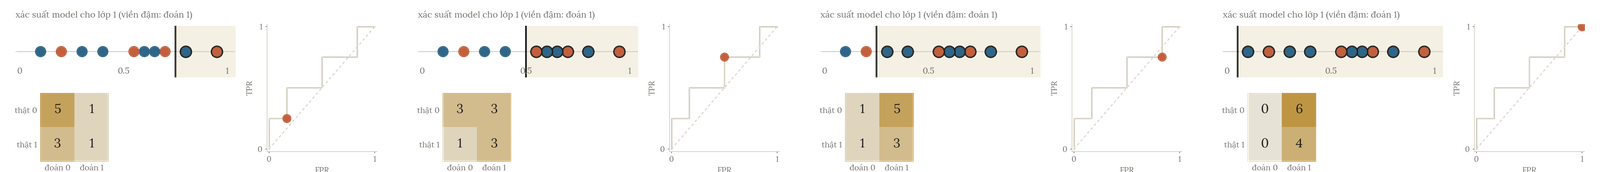

Với mảng validation, bốn score dương là 0.95, 0.70, 0.55, 0.20. Sáu score âm là 0.80, 0.65, 0.60, 0.40, 0.30, 0.10. Số cặp xếp đúng lần lượt là 6, 5, 3, 1: AUC $=15/(4\cdot6)=0.625$.

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

positive_scores = p_valid[y_valid == 1]
negative_scores = p_valid[y_valid == 0]
pair_points = []
for positive in positive_scores:
    for negative in negative_scores:
        pair_points.append(float(positive > negative) + 0.5 * float(positive == negative))
print(f'AUC tính theo cặp={np.mean(pair_points):.3f}')
print(f'AUC thư viện={roc_auc_score(y_valid, p_valid):.3f}')
print(f'Average precision={average_precision_score(y_valid, p_valid):.3f}')

AUC tính theo cặp=0.625
AUC thư viện=0.625
Average precision=0.653


Hai dòng AUC trùng nhau, xác nhận cách đếm cặp. Với lớp hiếm, ROC có thể trông tốt dù số báo nhầm tuyệt đối vẫn lớn, vì FPR chia cho một số TN khổng lồ; khi ấy nên đọc thêm đường precision–recall và average precision (AP), một cách tổng hợp precision khi recall tăng dần.

AUC cần cả hai lớp và phải nhận score liên tục, không dùng nhãn đã cắt 0/1 để đo khả năng xếp hạng. Nếu một fold chỉ có một lớp, hãy sửa phép đánh giá hoặc ghi rõ metric không xác định ở đó, không lặng lẽ thay bằng 1.

**Hỏi nhanh.** Hai mô hình xếp các mẫu theo đúng cùng một thứ tự score, chỉ khác nhau ở mức tự tin. ROC-AUC có phân biệt được hai mô hình này không?

- A. Có, vì AUC đo độ đúng của từng xác suất
- B. Có, vì AUC là accuracy ở ngưỡng 0.5
- C. Có, nếu một mô hình tự tin hơn hẳn
- D. Không, vì AUC chỉ phụ thuộc thứ tự score

<details><summary>Đáp án</summary>

D. Không, vì AUC chỉ phụ thuộc thứ tự score

AUC chỉ hỏi mẫu dương có được xếp trên mẫu âm hay không. Hai mô hình có cùng thứ tự score thì có cùng AUC, dù một bên tự tin hơn hẳn. Muốn chấm độ đúng của chính các xác suất, ta dùng một thước đo khác, chẳng hạn log loss ở mục sau.

</details>

## Xác suất và nhiều lớp

Log loss chấm mức xác suất chứ không chỉ nhãn. Với binary classification,

$$L=-\frac1n\sum_{i=1}^{n}\big[y_i\log p_i+(1-y_i)\log(1-p_i)\big].$$

$\log$ ở đây là logarithm tự nhiên. Đoán sai rất tự tin bị phạt nặng: với một mẫu dương, $p=0.01$ cho loss $-\log0.01\approx4.605$, còn $p=0.4$ cho khoảng 0.916. Thư viện xử lý xác suất sát 0 hoặc 1 để tránh `log(0)`; khi tự cài cần xem quy ước chính xác.



In [ ]:
from sklearn.metrics import log_loss

truth = np.array([1, 0])
confident_wrong = np.array([0.01, 0.99])
less_confident_wrong = np.array([0.4, 0.6])
print(f'Sai rất tự tin: log loss={log_loss(truth, confident_wrong):.3f}')
print(f'Sai ít tự tin: log loss={log_loss(truth, less_confident_wrong):.3f}')

Sai rất tự tin: log loss=4.605
Sai ít tự tin: log loss=0.916


Hai phương án đều đoán sai hai nhãn ở ngưỡng 0.5, nhưng log loss khác nhau. Xác suất được calibration tốt nghĩa là trong nhiều mẫu được đoán gần 0.7, khoảng 70% thật sự dương; phải kiểm điều ấy trên dữ liệu mới, không suy ra chỉ từ một score của một mẫu. Nếu trong 100 ca được đoán 0.9 chỉ có 60 ca dương thì mô hình quá tự tin. Hiệu chỉnh chỉ đổi con số xác suất, không đổi thứ tự xếp hạng.

Với nhiều lớp, tính F1 từng lớp bằng cách coi lớp ấy là dương. Trong ma trận nhầm lẫn nhiều lớp (hàng là nhãn thật), precision của một lớp đọc theo cột của lớp ấy, recall đọc theo hàng. Macro-F1 lấy trung bình đều giữa các lớp; weighted-F1 lấy trung bình theo số mẫu thật của lớp; micro gộp TP/FP/FN trước khi tính. Trong bài single-label nhiều lớp đầy đủ, micro-F1 trùng accuracy. Đề chấm macro-F1 thì lớp hiếm có trọng số bằng lớp lớn; không đổi sang weighted chỉ vì nó cao hơn.

**Hỏi nhanh.** Bài phân loại 3 lớp, đề chấm macro-F1. Lớp A chiếm 60% số mẫu, lớp B 35%, lớp C 5%. F1 của mô hình trên từng lớp là 0.95, 0.90 và 0.20. Weighted-F1 khoảng 0.90, còn macro-F1 chỉ 0.68. Ta nên làm gì tiếp?

- A. Báo weighted-F1 là 0.90, vì nó phản ánh phần lớn dữ liệu
- B. Báo accuracy, vì nó không phụ thuộc cách lấy trung bình
- C. Báo macro-F1 là 0.68, và tập trung cải thiện lớp C
- D. Gộp lớp C vào lớp gần nhất cho điểm cao hơn

<details><summary>Đáp án</summary>

C. Báo macro-F1 là 0.68, và tập trung cải thiện lớp C

Macro-F1 lấy trung bình đều ba lớp, nên lớp C hiếm kéo điểm xuống mạnh, và đó đúng là điều đề muốn đo. Nâng F1 của lớp C từ 0.20 lên 0.50 thì macro-F1 tăng 0.10, nhiều hơn mọi cải thiện còn có thể làm ở A hay B. Đổi sang metric khác hay gộp lớp là trả lời một câu hỏi khác với đề.

</details>

## Lớp hiếm

`class_weight` hay resampling có thể giúp model học lớp hiếm, nhưng không bảo đảm F1 tăng; resampling phải đặt trong train của mỗi fold, còn validation giữ nguyên phân phối thật. `class_weight='balanced'` đặt trọng số $n/(K\cdot n_c)$ cho lớp $c$, như 900 và 100 mẫu cho trọng số 0.56 và 5: mỗi lỗi ở lớp hiếm bị phạt nặng hơn mà không thêm, bớt mẫu nào.

**Hỏi nhanh.** Bài phát hiện gian lận có 9800 giao dịch hợp lệ và 200 giao dịch gian lận. Mô hình để mặc định thì đoán gần như tất cả là hợp lệ. Trong bốn cách sửa sau, cách nào vừa dễ làm vừa hiệu quả nhất?

- A. Dùng `class_weight` để lỗi trên lớp gian lận bị tính nặng hơn, giữ nguyên dữ liệu
- B. Nhân bản 200 mẫu gian lận lên thành 9800 mẫu
- C. Tạo thêm 9600 mẫu gian lận giả bằng cách pha trộn các mẫu thật
- D. Bỏ bớt 9600 giao dịch hợp lệ, chỉ học trên 400 mẫu

<details><summary>Đáp án</summary>

A. Dùng `class_weight` để lỗi trên lớp gian lận bị tính nặng hơn, giữ nguyên dữ liệu

`class_weight` khiến mỗi lỗi trên lớp gian lận bị tính nặng hơn khoảng 49 lần khi học, mà không thêm hay bớt dòng nào. Cách này rẻ và dùng được với hầu hết mô hình. Nhân bản mỗi mẫu gian lận 49 lần dễ khiến mô hình học thuộc đúng 200 mẫu ấy. Bỏ bớt dữ liệu là vứt đi 98% số giao dịch hợp lệ. Tạo mẫu giả có thể giúp, nhưng tốn công hơn và phải làm riêng trong từng fold. Dù chọn cách nào, ngưỡng vẫn phải chọn lại trên validation.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 275](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=101)

</details>

## Khi đi thi

- **Đọc metric và dạng output trước**: nhãn, xác suất hay score xếp hạng. Đề chấm AUC hay log loss thì nộp xác suất, đừng nộp nhãn 0/1.
- **In confusion matrix và tỉ lệ lớp**, không chỉ một con số.
- **Chọn threshold trên validation hoặc OOF**, rồi lưu threshold cùng model.
- **Đề chấm macro-F1** thì lớp hiếm nặng ngang lớp lớn: kiểm F1 từng lớp.

## Tóm tắt

- Precision hỏi độ đúng của cảnh báo; recall hỏi mức phát hiện dương thật.
- F1 kết hợp hai tỉ lệ và không trực tiếp sử dụng TN.
- Threshold chọn trên validation; test áp dụng quy tắc đã chốt.
- ROC-AUC đo thứ tự, log loss đo xác suất, macro-F1 cân đều lớp.

## Kiểm tra cuối bài

**Câu 1.** Có 10 000 giao dịch, trong đó 200 gian lận. Sau khi dùng `class_weight`, mô hình cho TP = 180, FP = 294, FN = 20, TN = 9506. Mỗi vụ gian lận bị bỏ sót gây thiệt hại khoảng 500 đơn vị. Mỗi cảnh báo nhầm chỉ tốn 1 đơn vị cho một lần kiểm tra bằng tay. Mô hình này có dùng được không?

- A. Rất tốt, vì accuracy là 96.9%, không cần xem gì thêm
- B. Không tốt, vì precision chỉ 38%, báo nhầm quá nhiều
- C. Chưa kết luận được khi chưa tính ROC-AUC
- D. Dùng được, vì recall 90% và báo nhầm rẻ hơn bỏ sót rất nhiều

<details><summary>Đáp án</summary>

D. Dùng được, vì recall 90% và báo nhầm rẻ hơn bỏ sót rất nhiều

Tổng thiệt hại là $20 \cdot 500 + 294 \cdot 1 = 10\,294$ đơn vị. Nếu đoán mọi giao dịch là hợp lệ, thiệt hại là $200 \cdot 500 = 100\,000$ đơn vị. Precision 38% đúng là thấp, nhưng ở đây một lần báo nhầm rẻ hơn 500 lần một lần bỏ sót. Accuracy gần như không khác mô hình “đoán hết là hợp lệ” (98%), nên không nói lên gì. ROC-AUC chấm thứ tự score, không chấm ngưỡng ta đã chọn để dùng.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 276](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=103)

</details>
**Câu 2.** Khi nào ta thường nên dùng F1 thay cho accuracy?

- A. Khi dữ liệu rất lớn, tới hàng triệu mẫu
- B. Khi số mẫu của các lớp gần bằng nhau
- C. Khi mô hình là mô hình tuyến tính
- D. Khi một lớp hiếm hơn hẳn lớp kia
- E. Khi có rất nhiều feature

<details><summary>Đáp án</summary>

D. Khi một lớp hiếm hơn hẳn lớp kia

Khi có lớp hiếm, accuracy bị lớp đông chi phối: đoán toàn lớp âm vẫn được điểm cao, như ví dụ 97% ở đầu bài. F1 chỉ nhìn TP, FP và FN của lớp dương, nên không bị số TN rất lớn che đi. Cỡ dữ liệu, loại mô hình hay số feature không quyết định việc chọn metric.
Đề thi: [USA-NA-AIO 2026 · Vòng 1 · Part 1.4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=2)

</details>
**Câu 3.** Có TP = 8, FP = 4, FN = 2. F1 của lớp dương bằng bao nhiêu?

- A. $11/15$
- B. $8/11$
- C. $2/3$
- D. $4/5$

<details><summary>Đáp án</summary>

B. $8/11$

$F_1 = 2TP/(2TP+FP+FN) = 16/22 = 8/11$. Precision là $2/3$, recall là $4/5$, còn $11/15$ là trung bình cộng của hai số ấy, không phải F1.

</details>
**Câu 4.** Một hệ thống có 98% giao dịch hợp lệ và 2% gian lận. Mô hình đoán tất cả là hợp lệ, nên accuracy là 98%. Bỏ sót gian lận thì tốn kém hơn báo nhầm. Ta kết luận được gì?

- A. Accuracy cao vẫn chưa đủ: recall trên lớp gian lận bằng 0, phải tính thiệt hại của từng loại lỗi
- B. Accuracy thật ra là 0%, vì mô hình không tìm được vụ gian lận nào
- C. Recall trên lớp gian lận cũng là 98%, vì bài hai lớp thì recall luôn bằng accuracy
- D. Accuracy 98% là đủ để kết luận mô hình dùng được

<details><summary>Đáp án</summary>

A. Accuracy cao vẫn chưa đủ: recall trên lớp gian lận bằng 0, phải tính thiệt hại của từng loại lỗi

Lớp hợp lệ chiếm đa số, nên accuracy vẫn cao dù mọi vụ gian lận đều bị bỏ sót. Metric phải bám theo mục tiêu khi dùng thật và thiệt hại của từng loại lỗi. F1 cũng không tự động là lựa chọn tốt nhất.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 274](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=100)

</details>
**Câu 5.** Quy tắc ra nhãn là: gán nhãn 1 khi $p \ge t$, với ngưỡng $t = 0.7$. Một mẫu có xác suất lớp dương $p = 0.7$ nhận nhãn gì?

- A. Nhãn 0, vì chỉ gán 1 khi $p > t$
- B. Nhãn 1, vì $p \ge t$
- C. Nhãn 0.7, vì quy tắc trả lại chính score
- D. Nhãn 1, vì mọi xác suất từ 0.5 trở lên đều được gán 1

<details><summary>Đáp án</summary>

B. Nhãn 1, vì $p \ge t$

Quy tắc dùng dấu $\ge$, nên trường hợp bằng đúng ngưỡng nhận nhãn 1. Khi viết code hay đọc đề, luôn ghi rõ dấu bằng nằm ở phía nào, vì score đúng bằng ngưỡng xuất hiện nhiều hơn ta tưởng.

</details>
**Câu 6.** Trên cùng tập validation, ta thử ba ngưỡng. Ngưỡng 0.3 cho FP = 30, FN = 2. Ngưỡng 0.5 cho FP = 12, FN = 6. Ngưỡng 0.7 cho FP = 4, FN = 12. Mỗi FP tốn 1 đơn vị, mỗi FN tốn 5 đơn vị, ngoài ra không có chi phí nào khác. Ta chọn ngưỡng nào?

- A. 0.5, vì tổng số lỗi ít nhất
- B. 0.7, vì FP ít nhất
- C. Chưa chọn được khi chưa biết accuracy
- D. 0.3, vì tổng chi phí là 40, thấp nhất

<details><summary>Đáp án</summary>

D. 0.3, vì tổng chi phí là 40, thấp nhất

Chi phí của ba ngưỡng lần lượt là $30 + 5\cdot 2 = 40$, $12 + 5\cdot 6 = 42$ và $4 + 5\cdot 12 = 64$. Ngưỡng 0.3 rẻ nhất. Đề tính theo chi phí, nên tổng số lỗi hay riêng số FP không phải là tiêu chí.

</details>
**Câu 7.** Xét 20 cặp gồm một mẫu dương và một mẫu âm. Có 12 cặp mẫu dương có score cao hơn, 4 cặp bằng nhau, 4 cặp thấp hơn. Cặp bằng nhau được tính nửa điểm. ROC-AUC bằng bao nhiêu?

- A. 0.80
- B. 0.75
- C. 0.70
- D. 0.60

<details><summary>Đáp án</summary>

C. 0.70

$\text{AUC} = (12 + 0.5\cdot 4)/20 = 0.70$. Bỏ qua các cặp bằng nhau thì ra 0.60. Tính chúng là thắng thì ra 0.80. Loại chúng khỏi mẫu số thì ra 0.75.

</details>
**Câu 8.** Đã có `p = model.predict_proba(X)[:, 1]`, nhãn dương là 1. Tính ROC-AUC bằng dòng nào?

- A. `roc_auc_score(y, p >= 0.5)`
- B. `roc_auc_score(y, p)`
- C. `roc_auc_score(p >= 0.5, y)`
- D. `roc_auc_score(y, p.mean() * np.ones_like(p))`

<details><summary>Đáp án</summary>

B. `roc_auc_score(y, p)`

`roc_auc_score` nhận nhãn thật trước, rồi đến score chưa cắt ngưỡng. Cắt `p >= 0.5` thì mất thông tin về thứ tự. Đảo hai đối số là đảo vai trò của nhãn và score. Còn score hằng số thì không xếp được mẫu nào trên mẫu nào.

</details>
**Câu 9.** Một mẫu có nhãn thật là 1. Mô hình A cho xác suất lớp 1 là 0.40, mô hình B cho 0.01. Ở ngưỡng 0.5, cả hai đều xếp mẫu này vào lớp 0. Theo log loss, mô hình nào bị phạt nặng hơn ở mẫu này?

- A. B, vì $-\log(0.01)$ lớn hơn $-\log(0.40)$
- B. A, vì 0.40 gần ngưỡng hơn
- C. Bằng nhau, vì cùng đoán ra nhãn 0
- D. B, vì log loss chỉ đếm số lần đoán lớp 0

<details><summary>Đáp án</summary>

A. B, vì $-\log(0.01)$ lớn hơn $-\log(0.40)$

Với nhãn thật là 1, log loss phạt $-\log p$. B sai mà gần như chắc chắn, nên bị phạt nặng hơn nhiều. Nhãn sau khi cắt ngưỡng không giữ được thông tin này.

</details>
**Câu 10.** Ba lớp có F1 là 0.90, 0.30 và 0.60. Số mẫu thật của chúng lần lượt là 80, 10 và 10. Macro-F1 bằng bao nhiêu?

- A. 0.81
- B. 0.90
- C. 0.60
- D. 0.30

<details><summary>Đáp án</summary>

C. 0.60

Macro-F1 lấy trung bình đều các lớp: $(0.90 + 0.30 + 0.60)/3 = 0.60$. Nếu lấy trung bình theo số mẫu thì được weighted-F1 là 0.81.

</details>
## Đọc thêm

- [scikit-learn — Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics). Tra averaging, ROC-AUC, AP và log loss theo đúng dạng đầu vào.
- [scikit-learn — Tuning the decision threshold](https://scikit-learn.org/stable/modules/classification_threshold.html). Đọc vì sao chọn threshold là một quyết định cần dữ liệu validation riêng.
- James và cộng sự — [An Introduction to Statistical Learning](https://www.statlearning.com/), chương 4. Đọc ý nghĩa score phân loại và các loại lỗi.